# ДЗ-1. Персональные top-10 рекомендации

Рекомендуем 10 незнакомых музыкальных объектов Amazon по истории отзывов. Объект — трек или альбом; релевантным считаем тот, которому пользователь поставил 4 или 5.

Датасет — Amazon Reviews 2018, Digital Music. Пять моделей реализованы в `models/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from data_utils import (download_data, load_data, split_data, build_stage,
                        TRAIN_END, VALIDATION_END, SEED)
from experiment_utils import GRIDS, CUSTOM_STRENGTHS, tune, final_comparison

np.random.seed(SEED)
thread_limit = threadpool_limits(limits=2)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Данные

[Первоисточник](https://nijianmo.github.io/amazon/index.html) · [Скачать 5-core файл](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Digital_Music_5.json.gz).

Полная категория содержит 1 584 082 отзыва, опубликованный 5-core — 169 781. Берём весь 5-core: авторы оставили пользователей и объекты с минимум пятью отзывами. После удаления повторов этот минимум может уменьшиться.

`reviewerID`, `asin` — пользователь и объект; `overall` — оценка 1–5; `unixReviewTime` — время отзыва; `verified` — подтверждённая покупка. Тексты отзывов не используем.

In [2]:
path = download_data()
raw, clean, data_report = load_data(path)
display(pd.DataFrame([
    {'stage': '5-core file', 'interactions': len(raw), 'users': raw.user.nunique(), 'items': raw.item.nunique()},
    {'stage': 'after cleaning', 'interactions': len(clean), 'users': clean.user.nunique(), 'items': clean.item.nunique()},
]))
print('Period:', clean.timestamp.min(), '—', clean.timestamp.max())

,stage,interactions,users,items
0,5-core file,169781,16566,11797
1,after cleaning,145292,16566,11797


Period: 1998-07-09 00:00:00+00:00 — 2018-09-26 00:00:00+00:00


## 2. Подготовка и EDA

Удаляем строки без обязательных полей и с некорректной оценкой или датой. Для повторной пары пользователь–объект сохраняем первый отзыв по времени; при равной дате — первый в файле. Так уже известный объект не попадёт в будущие рекомендации.

Пропущенный `verified` заменяем на 0. Разреженность считаем по всем очищенным взаимодействиям. Ниже проверяем пропуски, повторы, активность, популярность, оценки и метаданные.

user         0
item         0
rating       0
timestamp    0
verified     0
Name: missing values, dtype: int64

raw_rows                   169781.000000
raw_users                   16566.000000
raw_items                   11797.000000
duplicate_used_fields       23847.000000
invalid_or_missing_rows         0.000000
repeated_user_item_rows     24489.000000
clean_rows                 145292.000000
clean_users                 16566.000000
clean_items                 11797.000000
sparsity                        0.999257
Name: value, dtype: float64

,user_activity,item_popularity
count,16566.000000,11797.000000
mean,8.770494,12.316013
std,10.212211,15.689818
min,1.000000,1.000000
25%,5.000000,6.000000
50%,6.000000,8.000000
75%,9.000000,13.000000
max,557.000000,572.000000


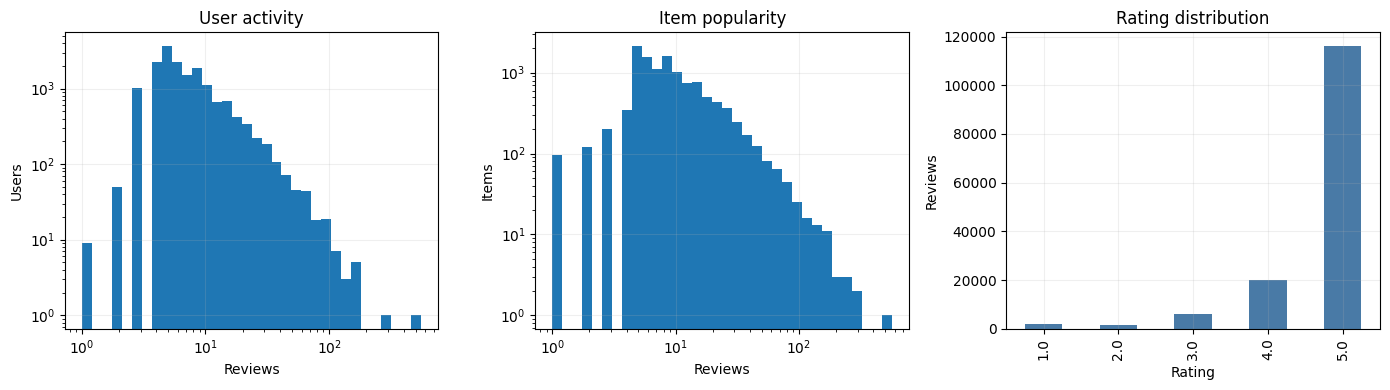

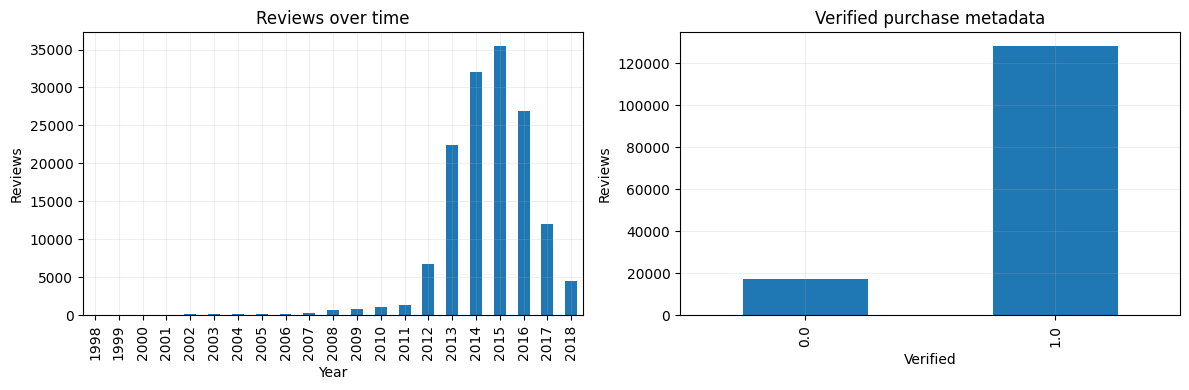

,count,mean
verified,,
0.0,17024,4.424460
1.0,128268,4.733519


In [3]:
display(pd.Series(data_report['missing'], name='missing values'))
display(pd.Series({k: v for k, v in data_report.items() if k not in ['missing']}, name='value'))
activity = clean.groupby('user').size()
popularity = clean.groupby('item').size()
display(pd.DataFrame({'user_activity': activity.describe(), 'item_popularity': popularity.describe()}))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(activity, bins=np.geomspace(1, activity.max()+1, 35))
axes[0].set(xscale='log', yscale='log', title='User activity', xlabel='Reviews', ylabel='Users')
axes[1].hist(popularity, bins=np.geomspace(1, popularity.max()+1, 35))
axes[1].set(xscale='log', yscale='log', title='Item popularity', xlabel='Reviews', ylabel='Items')
clean.rating.value_counts().sort_index().plot.bar(ax=axes[2], color='#497aa6')
axes[2].set(title='Rating distribution', xlabel='Rating', ylabel='Reviews')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
clean.groupby(clean.timestamp.dt.year).size().plot.bar(ax=axes[0])
axes[0].set(title='Reviews over time', xlabel='Year', ylabel='Reviews')
clean.groupby('verified').rating.agg(['count', 'mean']).reset_index().plot.bar(x='verified', y='count', ax=axes[1], legend=False)
axes[1].set(title='Verified purchase metadata', xlabel='Verified', ylabel='Reviews')
plt.tight_layout()
plt.show()
display(clean.groupby('verified').rating.agg(['count', 'mean']))

## 3. Оценка

Разбиение общее по времени (UTC): train — до 2015-01-01, validation — 2015 год, test — с 2016-01-01. Параметры выбираем на validation, затем переобучаем модели на train + validation и оцениваем на test.

Кандидаты — весь каталог из доступной истории без объектов, которые пользователь уже оценивал, включая оценки 1–3. Оцениваем пользователей с минимум тремя положительными отзывами, десятью кандидатами и хотя бы одним релевантным объектом в будущем периоде. Новых пользователей и объекты исключаем; потери показаны в таблицах.

Для всех моделей одинаковые пользователи, кандидаты и релевантность: оценка ≥4. Список строится на начало периода, история внутри test не обновляется. При равных scores порядок определяется ASIN.

Основная метрика — **NDCG@10**, учитывающая позиции попаданий. **Recall@10** показывает долю найденных релевантных объектов. Усредняем по пользователям. Объект без положительной оценки в отложенных данных попаданием не считается.

In [4]:
train, validation, test = split_data(clean)
display(pd.DataFrame([
    {'split': name, 'rows': len(frame), 'users': frame.user.nunique(), 'items': frame.item.nunique(),
     'start': frame.timestamp.min(), 'end': frame.timestamp.max()}
    for name, frame in [('train', train), ('validation', validation), ('test', test)]
]))
validation_stage = build_stage(train, validation, TRAIN_END)
display(pd.Series(validation_stage['diagnostics'], name='validation protocol'))

,split,rows,users,items,start,end
0,train,66365,11374,10110,1998-07-09 00:00:00+00:00,2014-12-31 00:00:00+00:00
1,validation,35490,7580,9307,2015-01-01 00:00:00+00:00,2015-12-31 00:00:00+00:00
2,test,43437,7763,9992,2016-01-01 00:00:00+00:00,2018-09-26 00:00:00+00:00


history_rows               66365
positive_history           61289
users                      11374
catalogue_items            10110
future_rows                35490
future_positive_rows       33423
cold_user_positive_rows    17970
cold_item_positive_rows     6525
cold_any_positive_rows     21736
inactive_positive_rows      5333
evaluated_users             2001
evaluated_positive_rows     6354
Name: validation protocol, dtype: int64

### Признаки FM

Помимо ID используем активность пользователя, популярность объекта, его возраст с первого отзыва и доли подтверждённых покупок пользователя и объекта. Они описывают полноту истории, известность объекта и характер взаимодействий.

К количествам отзывов и возрасту применяем `log(1 + x)`, затем стандартизуем все пять признаков. Считаем их только по доступной истории на дату рекомендации. Будущие оценки и `verified` не используем; возраст здесь не равен времени с релиза.

,log_activity,verified_share
count,11374.000000,11374.000000
mean,1.694001,0.817565
std,0.620907,0.310418
min,0.693147,0.000000
25%,1.386294,0.750000
50%,1.609438,1.000000
75%,1.945910,1.000000
max,6.021023,1.000000


,log_popularity,log_age_days,verified_share
count,10110.000000,10110.000000,10110.000000
mean,1.734954,6.425544,0.839736
std,0.674858,0.931557,0.237625
min,0.693147,0.693147,0.000000
25%,1.386294,6.156979,0.750000
50%,1.609438,6.566672,1.000000
75%,2.079442,6.840547,1.000000
max,5.996452,8.703009,1.000000


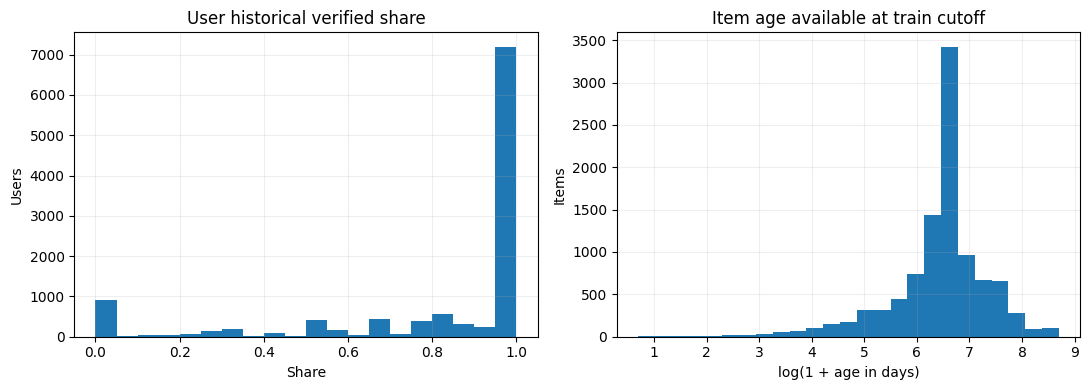

In [5]:
display(validation_stage['raw_user_features'].describe())
display(validation_stage['raw_item_features'].describe())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
validation_stage['raw_user_features'].verified_share.hist(bins=20, ax=axes[0])
axes[0].set(title='User historical verified share', xlabel='Share', ylabel='Users')
validation_stage['raw_item_features'].log_age_days.hist(bins=25, ax=axes[1])
axes[1].set(title='Item age available at train cutoff', xlabel='log(1 + age in days)', ylabel='Items')
plt.tight_layout()
plt.show()

## 4. Модели

$X_{ui}=1$, если в истории есть оценка ≥4, иначе 0. Формирование top-10 и метрики общие для всех моделей.

**ItemKNN:** косинусная близость со снижением веса малых пересечений:
$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+h},\quad n_{ij}=X_i^TX_j,\quad s_{ii}=0.$$
Для каждого объекта оставляем $k$ соседей; оценка — $\hat r_{ui}=\sum_jX_{uj}s_{ji}$ по оставленным связям.

**iALS:** по очереди обучаем векторы пользователей и объектов:
$$\min_{A,B}\sum_{ui}c_{ui}(X_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2),\quad c_{ui}=1+\alpha X_{ui}.$$
В сумму входят и ненаблюдаемые пары. Обновления получаем решением линейных систем; score — $a_u^Tb_i$.

**EASE:** минимизируем $\|X-XW\|_F^2+\lambda\|W\|_F^2$ при нулевой диагонали:
$$P=(X^TX+\lambda I)^{-1},\quad W_{ij}=-P_{ij}/P_{jj}\ (i\ne j),\quad W_{ii}=0,\quad \hat R=XW.$$

**FM:** учитываем попарные взаимодействия признаков:
$$f(x)=w_0+\sum_jw_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$
Обучаем бинарную cross-entropy с L2, используя собственные градиенты и Adam. Положительные примеры — оценки ≥4; отрицательные — оценки 1–3 и две случайные неизвестные пары на положительную. При сэмплировании исключаем известную историю, не заглядывая в validation/test. Ранжируем по логиту.

**CustomALS:** заменяем бинарный таргет на сигнал из оценки и привычек пользователя:
$$\mu_u=\frac{\sum_{i\in H_u}r_{ui}+5\bar r}{|H_u|+5},$$
$$q_{ui}=1+\frac{\beta}{2}\left[\frac{r_{ui}-4.5}{0.5}+\tanh(r_{ui}-\mu_u)\right]\quad\text{при }r_{ui}\ge4;\qquad q_{ui}=0\text{ иначе}.$$
$H_u$ — история пользователя, $\bar r$ — средняя оценка в обучении. Идея: различать 4 и 5 и выделять оценки выше обычных для автора. Сглаживание средней уменьшает влияние коротких историй.

В функции потерь iALS меняем $X$ на $q$ как целевой сигнал. Confidence и остальные параметры оставляем как у выбранного iALS; подбираем только $\beta\in\{0.25,0.75\}$. При $\beta=0$ получаем базовый iALS.

Сетки параметров приведены ниже. Выбираем максимум validation NDCG@10; при равенстве — первый вариант. Seed = 42. Дополнительно сравниваем FM с версией только на ID при одинаковых настройках.

In [6]:
display(pd.DataFrame([{'model': name, 'trial': i+1, 'params': params}
                      for name, grid in GRIDS.items() for i, params in enumerate(grid)]))
print('CustomALS: selected iALS parameters + strength in', CUSTOM_STRENGTHS)
print('Primary metric fixed before search: NDCG@10')

,model,trial,params
0,ItemKNN,1,"{'neighbors': 30, 'shrinkage': 0}"
1,ItemKNN,2,"{'neighbors': 30, 'shrinkage': 20}"
2,ItemKNN,3,"{'neighbors': 100, 'shrinkage': 0}"
3,ItemKNN,4,"{'neighbors': 100, 'shrinkage': 20}"
4,iALS,1,"{'factors': 16, 'regularization': 1.0, 'alpha'..."
5,iALS,2,"{'factors': 16, 'regularization': 10.0, 'alpha..."
6,iALS,3,"{'factors': 32, 'regularization': 1.0, 'alpha'..."
7,iALS,4,"{'factors': 32, 'regularization': 10.0, 'alpha..."
8,EASE,1,{'regularization': 50.0}
9,EASE,2,{'regularization': 200.0}


CustomALS: selected iALS parameters + strength in [0.25, 0.75]
Primary metric fixed before search: NDCG@10


In [7]:
# This function receives validation data only; test is not passed to tuning.
validation_results, selected = tune(validation_stage)
display(validation_results.sort_values(['model', 'NDCG@10'], ascending=[True, False]))
display(pd.DataFrame([{'model': name, 'selected_params': params} for name, params in selected.items()]))

Validation: ItemKNN {'neighbors': 30, 'shrinkage': 0}


Validation: ItemKNN {'neighbors': 30, 'shrinkage': 20}


Validation: ItemKNN {'neighbors': 100, 'shrinkage': 0}


Validation: ItemKNN {'neighbors': 100, 'shrinkage': 20}


Validation: iALS {'factors': 16, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 10, 'seed': 42}


...

Validation: FM {'factors': 16, 'epochs': 16, 'learning_rate': 0.01, 'regularization': 0.0001, 'negatives': 2, 'batch_size': 2048, 'metadata': True, 'seed': 42}


Validation: CustomALS {'factors': 16, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 10, 'seed': 42, 'strength': 0.25}


Validation: CustomALS {'factors': 16, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 10, 'seed': 42, 'strength': 0.75}


,model,params,NDCG@10,Recall@10
13,CustomALS,"{'factors': 16, 'regularization': 10.0, 'alpha...",0.017834,0.027849
12,CustomALS,"{'factors': 16, 'regularization': 10.0, 'alpha...",0.017583,0.024373
9,EASE,{'regularization': 200.0},0.021683,0.030887
8,EASE,{'regularization': 50.0},0.021617,0.030949
10,FM,"{'factors': 16, 'epochs': 8, 'learning_rate': ...",0.007858,0.009042
11,FM,"{'factors': 16, 'epochs': 16, 'learning_rate':...",0.007566,0.012971
3,ItemKNN,"{'neighbors': 100, 'shrinkage': 20}",0.018707,0.028865
1,ItemKNN,"{'neighbors': 30, 'shrinkage': 20}",0.018337,0.027929
2,ItemKNN,"{'neighbors': 100, 'shrinkage': 0}",0.015064,0.023936
0,ItemKNN,"{'neighbors': 30, 'shrinkage': 0}",0.013884,0.022833


,model,selected_params
0,ItemKNN,"{'neighbors': 100, 'shrinkage': 20}"
1,iALS,"{'factors': 16, 'regularization': 10.0, 'alpha..."
2,EASE,{'regularization': 200.0}
3,FM,"{'factors': 16, 'epochs': 8, 'learning_rate': ..."
4,CustomALS,"{'factors': 16, 'regularization': 10.0, 'alpha..."
5,FM_ID_only,"{'factors': 16, 'epochs': 8, 'learning_rate': ..."


## 5. Результаты

Обучаем выбранные модели на train + validation, проверяем на test. Для FM отдельно убираем метапризнаки при тех же настройках.

In [8]:
final_stage = build_stage(pd.concat([train, validation], ignore_index=True), test, VALIDATION_END)
display(pd.DataFrame({'validation': validation_stage['diagnostics'], 'test': final_stage['diagnostics']}))

final_results = final_comparison(final_stage, selected)
main_results = final_results[final_results.model != 'FM_ID_only'].sort_values('NDCG@10', ascending=False)
display(main_results[['model', 'NDCG@10', 'Recall@10', 'params']])
display(final_results[final_results.model.isin(['FM', 'FM_ID_only'])][['model', 'NDCG@10', 'Recall@10', 'params']])

,validation,test
history_rows,66365,101855
positive_history,61289,94712
users,11374,14368
catalogue_items,10110,11234
future_rows,35490,43437
future_positive_rows,33423,41177
cold_user_positive_rows,17970,19368
cold_item_positive_rows,6525,5728
cold_any_positive_rows,21736,23332
inactive_positive_rows,5333,6692


Test: ItemKNN


Test: iALS


Test: EASE


Test: FM


Test: CustomALS


Test: FM_ID_only


,model,NDCG@10,Recall@10,params
2,EASE,0.017775,0.027565,{'regularization': 200.0}
0,ItemKNN,0.015680,0.024443,"{'neighbors': 100, 'shrinkage': 20}"
1,iALS,0.014055,0.022797,"{'factors': 16, 'regularization': 10.0, 'alpha..."
4,CustomALS,0.013911,0.022886,"{'factors': 16, 'regularization': 10.0, 'alpha..."
3,FM,0.009738,0.011842,"{'factors': 16, 'epochs': 8, 'learning_rate': ..."


,model,NDCG@10,Recall@10,params
3,FM,0.009738,0.011842,"{'factors': 16, 'epochs': 8, 'learning_rate': ..."
5,FM_ID_only,0.003749,0.004462,"{'factors': 16, 'epochs': 8, 'learning_rate': ..."


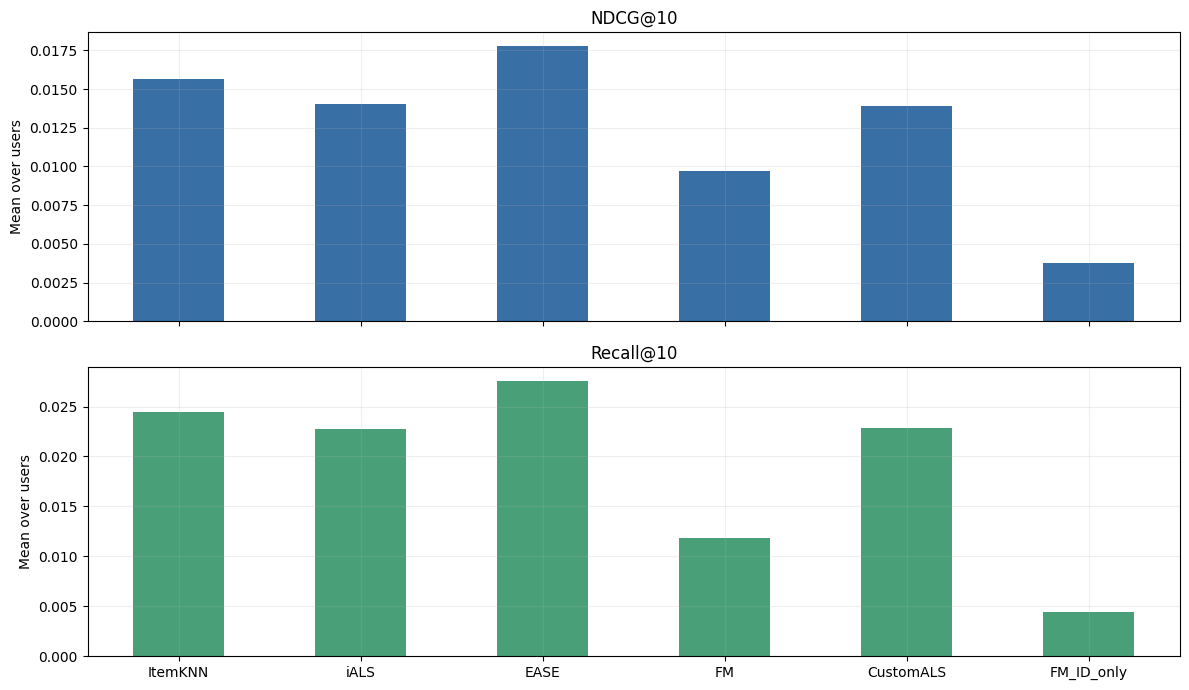

In [9]:
plot = final_results.set_index('model')[['NDCG@10', 'Recall@10']]
axes = plot.plot.bar(subplots=True, figsize=(12, 7), color=['#386fa4', '#49a078'], legend=False, rot=0)
for ax in axes:
    ax.set_ylabel('Mean over users')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

## 6. Выводы

EASE с регуляризацией 200 лучший по обеим метрикам: NDCG@10 = 0.01777, Recall@10 = 0.02757. Метапризнаки улучшили FM: NDCG@10 вырос с 0.00375 до 0.00974 при одинаковых настройках.

Кастомный таргет не улучшил NDCG@10 iALS: 0.01391 против 0.01405.

Результаты ограничены одним seed, небольшой сеткой и пользователями с накопленной историей. Исходный 5-core отобран по всему периоду, а история внутри test не обновляется. Отсутствие отзыва не означает, что объект не понравился.